# Per-fish and per-pair factors for my model, from sure-emitter EODs (five 4-fish videos, Kaden masks)

Data: `kaden_4fish_assign.py` on five random 4-fish videos of 2024-02-20 (re-synchronised EOD tables in `data/4 fish`, Kaden's
masks, letters A–D = the same four fish in every video; no frame offset). My model: BEM conductivities, sink at the tail tip,
unit current; $m_{i,f,p}$ = predicted voltage of pair p if fish f emits EOD i (× −1, sign fixed); $r_{i,p}$ = recorded peak pattern (V).

**Sure-emitter EODs.** Fish f is taken as the emitter of EOD i when all of these hold:
1. **far from the others**: the smallest distance from f's mask midline to every other fish's midline is ≥ `ISO_CM`
   (midline points ~0.75 cm apart; the mask-edge gap is about 1 cm less);
2. **a pair that only f lights up**: at $p^* = \arg\max_p |m_{i,f,p}|$, f's predicted |v| is ≥ `DOM` × that of every other fish;
3. **the recording agrees**: the largest recorded |v| is at $p^*$, with the sign f's model predicts there;
4. only one fish passes 1–3.

**Joint fit.** $r_{i,p} \approx a_f\, b_p\, m_{i,f,p}$ with f the sure emitter of EOD i: 4 per-fish factors $a_f$ and 10 per-pair
factors $b_p$, shared by all fish. Alternating least squares; each EOD divided by its own $\lVert r_i\rVert$ so that every EOD counts
the same (EODs next to an electrode are otherwise ~100× louder); the same fit without that weighting is shown for comparison.
$a_f b_p$ is unchanged by $a\to ca$, $b \to b/c$, so the pair factors are normalised to a geometric mean of 1 and $a_f$ carries the
gain in V per model unit. Uncertainty: 95% bootstrap intervals over EODs, and the spread of fits made on each video alone.
**Check**: leave-one-video-out — fit on four videos, relative residual $\lVert r - \hat r\rVert / \lVert r\rVert$ on the fifth, for one
global gain, per-fish only, per-pair only, and per-fish × per-pair.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

RECS = ['05_52_55', '06_52_55', '11_12_57', '15_16_23', '19_16_25']
BASE, LET, P = 'results/eod_assign_4fish_kaden', 'ABCD', 912
ISO_CM, DOM = 15.0, 2.0
OUT = f'{BASE}/fish_pair_factors' + ('' if (ISO_CM, DOM) == (15.0, 5.0) else f'_iso{ISO_CM:g}cm_dom{DOM:g}'); os.makedirs(OUT, exist_ok=True)
PX_CM = 912 / 60
FISH_COL = {'A': '#1F5FBF', 'B': '#17A0B0', 'C': '#F08A24', 'D': '#C8361E'}
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.color': '#e6e6e3',
                     'axes.edgecolor': '#8a8a85', 'axes.labelcolor': '#2b2b2b', 'xtick.color': '#5a5a55', 'ytick.color': '#5a5a55'})

## Sure-emitter EODs

In [2]:
def gaps_cm(mids):
    '''(n_frames, 4): smallest midline-to-midline distance (cm) from each fish to any other fish; NaN without midlines.'''
    xy = mids[:, :, ::5] * (P - 1) / PX_CM                                     # every 5th of 101 points (~0.75 cm apart)
    g = np.full(mids.shape[:2], np.inf)
    for f in range(4):
        for h in range(4):
            if h == f: continue
            d = np.linalg.norm(xy[:, f, :, None] - xy[:, h, None], axis=-1).min(axis=(1, 2))
            g[:, f] = np.minimum(g[:, f], d)
    return np.where(np.isfinite(g), g, np.nan)

rows, R_all, M_all = [], [], []
for t in RECS:
    z = np.load(f'{BASE}/{t}/predicted_voltages.npz')
    R, M = z['recorded_peak'], z['mine_unit_current']                          # (n, 10) V, (n, 4, 10) model x -1
    mz = np.load(f'{BASE}/{t}/midlines_by_frame.npz'); gi = {k: i for i, k in enumerate(mz['frames'])}
    G = gaps_cm(mz['mids'])[[gi[k] for k in z['frame']]]                        # (n, 4)
    absM = np.abs(M); pstar = np.nanargmax(np.where(np.isfinite(absM), absM, -1), axis=2)   # (n, 4)
    n = len(R); ii = np.arange(n)
    ok = np.zeros((n, 4), bool)
    for f in range(4):
        p = pstar[:, f]
        own = absM[ii, f, p]
        other = np.nanmax(np.delete(absM, f, axis=1)[ii, :, p], axis=1)
        rec_top = np.nanargmax(np.abs(R), axis=1) == p
        sign_ok = np.sign(R[ii, p]) == np.sign(M[ii, f, p])
        ok[:, f] = (G[:, f] >= ISO_CM) & (own >= DOM * other) & rec_top & sign_ok & np.isfinite(M[:, f]).all(1)
    one = ok.sum(1) == 1
    em = np.where(one, ok.argmax(1), -1)
    sel = np.flatnonzero(one)
    rows.append(pd.DataFrame({'video': t, 'row': sel, 'Frame': z['frame'][sel], 'emitter': np.array(list(LET))[em[sel]],
                              'pair p* (1-10)': pstar[sel, em[sel]] + 1, 'gap (cm)': G[sel, em[sel]]}))
    R_all.append(R[sel]); M_all.append(M[sel, em[sel]])
    print(f'{t}: {n} EODs, isolated fish-EODs {int((G >= ISO_CM).sum())}, sure emitter {len(sel)} '
          f'(dropped: >1 fish passes {int((ok.sum(1) > 1).sum())})')
S = pd.concat(rows, ignore_index=True); Rs = np.concatenate(R_all); Ms = np.concatenate(M_all)
S.to_csv(f'{OUT}/sure_emitter_eods.csv', index=False)
display(pd.crosstab(S.video, S.emitter, margins=True))
display(pd.crosstab(S.emitter, S['pair p* (1-10)'], margins=True))

05_52_55: 52051 EODs, isolated fish-EODs 72110, sure emitter 9231 (dropped: >1 fish passes 0)


06_52_55: 53817 EODs, isolated fish-EODs 63480, sure emitter 9217 (dropped: >1 fish passes 0)


11_12_57: 39141 EODs, isolated fish-EODs 29009, sure emitter 1167 (dropped: >1 fish passes 0)


15_16_23: 59496 EODs, isolated fish-EODs 55392, sure emitter 6780 (dropped: >1 fish passes 0)


19_16_25: 60238 EODs, isolated fish-EODs 13370, sure emitter 2387 (dropped: >1 fish passes 0)


emitter,A,B,C,D,All
video,,,,,
05_52_55,4005,1282,2096,1848,9231
06_52_55,1349,6436,132,1300,9217
11_12_57,0,556,0,611,1167
15_16_23,271,6326,74,109,6780
19_16_25,51,2173,70,93,2387
All,5676,16773,2372,3961,28782


pair p* (1-10),1,2,3,4,5,6,7,8,9,10,All
emitter,,,,,,,,,,,
A,238,195,148,580,1617,886,978,564,287,183,5676
B,4184,5843,2544,16,0,301,503,974,202,2206,16773
C,361,102,135,163,412,201,580,324,24,70,2372
D,157,109,44,211,137,436,2363,254,61,189,3961
All,4940,6249,2871,970,2166,1824,4424,2116,574,2648,28782


## Joint fit: per-fish × per-pair

In [3]:
FI = S.emitter.map({f: i for i, f in enumerate(LET)}).to_numpy()

def fit(R, M, fi, fish=True, pair=True, weight=True, iters=200):
    '''Least-squares a (4,), b (10,) with R ~ a[fi, None] * b[None] * M; rows weighted by 1 / ||r|| if weight; geo-mean(b) = 1.'''
    w = 1 / np.linalg.norm(R, axis=1, keepdims=True) if weight else np.ones((len(R), 1))
    Rw, Mw = R * w, M * w
    a, b = np.ones(4), np.ones(10)
    for _ in range(iters):
        X = Mw * b                                                            # update a (one per fish, or one shared)
        if fish: a = np.array([(Rw[fi == f] * X[fi == f]).sum() / (X[fi == f] ** 2).sum() if (fi == f).any() else np.nan for f in range(4)])
        else: a = np.full(4, (Rw * X).sum() / (X ** 2).sum())
        if pair:
            Y = Mw * a[fi, None]; b = (Rw * Y).sum(0) / (Y ** 2).sum(0); b = b / np.exp(np.mean(np.log(np.abs(b))))
    return a, b

def rel_resid(R, M, fi, a, b):
    return np.linalg.norm(R - a[fi, None] * b[None] * M, axis=1) / np.linalg.norm(R, axis=1)

a, b = fit(Rs, Ms, FI); a_u, b_u = fit(Rs, Ms, FI, weight=False)
rng = np.random.default_rng(0); boot = []
for _ in range(300):
    i = rng.integers(0, len(Rs), len(Rs)); boot.append(np.r_[fit(Rs[i], Ms[i], FI[i], iters=60)])
boot = np.array(boot)
lo, hi = np.percentile(boot, [2.5, 97.5], axis=0)
per_video = np.array([np.r_[fit(Rs[S.video == t], Ms[S.video == t], FI[S.video == t])] for t in RECS])
names = [f'fish {f}' for f in LET] + [f'pair {p}' for p in range(1, 11)]
F = pd.DataFrame({'factor': np.r_[a, b], '95% low': lo, '95% high': hi, 'unweighted fit': np.r_[a_u, b_u],
                  **{f'video {t} alone': per_video[j] for j, t in enumerate(RECS)}}, index=names)
F['n EODs'] = [int((FI == f).sum()) for f in range(4)] + [int((S['pair p* (1-10)'] == p).sum()) for p in range(1, 11)]
F.to_csv(f'{OUT}/fish_pair_factors.csv')
display(F.round(3))

,factor,95% low,95% high,unweighted fit,video 05_52_55 alone,video 06_52_55 alone,video 11_12_57 alone,video 15_16_23 alone,video 19_16_25 alone,n EODs
fish A,0.243,0.212,0.274,0.446,0.237,0.320,NaN,0.224,0.307,5676
fish B,0.156,0.150,0.162,0.268,0.119,0.227,0.152,0.102,0.230,16773
fish C,0.289,0.267,0.309,0.432,0.328,0.301,NaN,0.059,0.229,2372
fish D,0.309,0.298,0.320,0.397,0.264,0.357,0.475,0.168,0.237,3961
pair 1,1.223,1.187,1.262,0.985,0.969,0.777,1.744,2.265,1.343,4940
pair 2,0.833,0.799,0.868,0.735,1.013,0.943,0.436,0.236,0.588,6249
pair 3,0.644,0.609,0.675,0.715,1.095,0.770,0.230,0.155,1.484,2871
pair 4,1.092,0.994,1.185,0.890,1.123,0.800,2.020,1.292,1.446,970
pair 5,1.559,1.431,1.676,1.111,1.581,1.384,1.149,1.850,1.606,2166
pair 6,0.791,0.714,0.868,1.333,0.570,1.202,1.002,1.025,0.650,1824


## Leave-one-video-out check

In [4]:
def fit_table(R, M, fi, weight=True):
    '''(4, 10) gain g[f, p], one per fish per pair, each fitted on its own (same 1/||r|| weighting); a fish-pair cell with no
    training EODs at all falls back to the per-fish × per-pair product.'''
    w = 1 / np.linalg.norm(R, axis=1, keepdims=True) if weight else np.ones((len(R), 1))
    Rw, Mw = R * w, M * w
    a, b = fit(R, M, fi, weight=weight)
    g = a[:, None] * b[None]
    for f in range(4):
        m = fi == f
        if m.any(): g[f] = np.where((Mw[m] ** 2).sum(0) > 0, (Rw[m] * Mw[m]).sum(0) / np.maximum((Mw[m] ** 2).sum(0), 1e-300), g[f])
    return g

MODELS = {'one global gain': dict(fish=False, pair=False), 'per-fish only (4)': dict(fish=True, pair=False),
          'per-pair only (10)': dict(fish=False, pair=True), 'per-fish × per-pair (4 + 10)': dict(fish=True, pair=True),
          'per-fish-per-pair table (40)': None}
cv, tab = [], []
for t in RECS:
    tr, te = (S.video != t).to_numpy(), (S.video == t).to_numpy()
    for nm, kw in MODELS.items():
        if kw is None:
            g = fit_table(Rs[tr], Ms[tr], FI[tr])
            e = np.linalg.norm(Rs[te] - g[FI[te]] * Ms[te], axis=1) / np.linalg.norm(Rs[te], axis=1)
            tab += [{'held-out video': t, 'model': nm, 'factor': f'fish {f} × pair {p + 1}', 'value': g[j, p]} for j, f in enumerate(LET) for p in range(10)]
        else:
            aa, bb = fit(Rs[tr], Ms[tr], FI[tr], **kw)
            e = rel_resid(Rs[te], Ms[te], FI[te], aa, bb)
            if nm.startswith('per-fish ×'):
                tab += [{'held-out video': t, 'model': nm, 'factor': n, 'value': v} for n, v in zip(names, np.r_[aa, bb])]
        cv.append({'held-out video': t, 'model': nm, 'median relative residual': np.median(e), 'mean relative residual': e.mean(), 'n EODs': te.sum()})
CV = pd.DataFrame(cv); CV.to_csv(f'{OUT}/leave_one_video_out.csv', index=False)
TAB = pd.DataFrame(tab).pivot_table(index=['model', 'factor'], columns='held-out video', values='value', sort=False)
TAB.columns = [f'fit without {c}' for c in TAB.columns]; TAB.to_csv(f'{OUT}/factors_fit_on_4_videos.csv')
display(CV.pivot_table(index='held-out video', columns='model', values='median relative residual', sort=False).round(3))
display(CV.groupby('model', sort=False)[['median relative residual', 'mean relative residual']].mean().round(3))
display(TAB.loc['per-fish × per-pair (4 + 10)'].round(3))

model,one global gain,per-fish only (4),per-pair only (10),per-fish × per-pair (4 + 10),per-fish-per-pair table (40)
held-out video,,,,,
05_52_55,0.700,0.427,0.534,0.486,0.365
06_52_55,0.447,0.548,0.686,0.678,0.722
11_12_57,0.643,0.577,0.627,0.530,0.453
15_16_23,0.394,0.459,0.384,0.443,0.466
19_16_25,0.573,0.632,0.634,0.686,0.712


,median relative residual,mean relative residual
model,,
one global gain,0.552,0.652
per-fish only (4),0.529,0.608
per-pair only (10),0.573,0.622
per-fish × per-pair (4 + 10),0.564,0.620
per-fish-per-pair table (40),0.543,0.593


,fit without 05_52_55,fit without 06_52_55,fit without 11_12_57,fit without 15_16_23,fit without 19_16_25
factor,,,,,
fish A,0.306,0.212,0.246,0.245,0.238
fish B,0.161,0.127,0.154,0.197,0.148
fish C,0.142,0.261,0.291,0.328,0.288
fish D,0.365,0.257,0.292,0.326,0.307
pair 1,1.391,1.490,1.217,0.928,1.208
pair 2,0.798,0.409,0.858,1.003,0.876
pair 3,0.544,0.620,0.674,0.922,0.563
pair 4,0.943,1.275,1.103,1.037,1.093
pair 5,1.154,1.776,1.559,1.533,1.581


## Figures

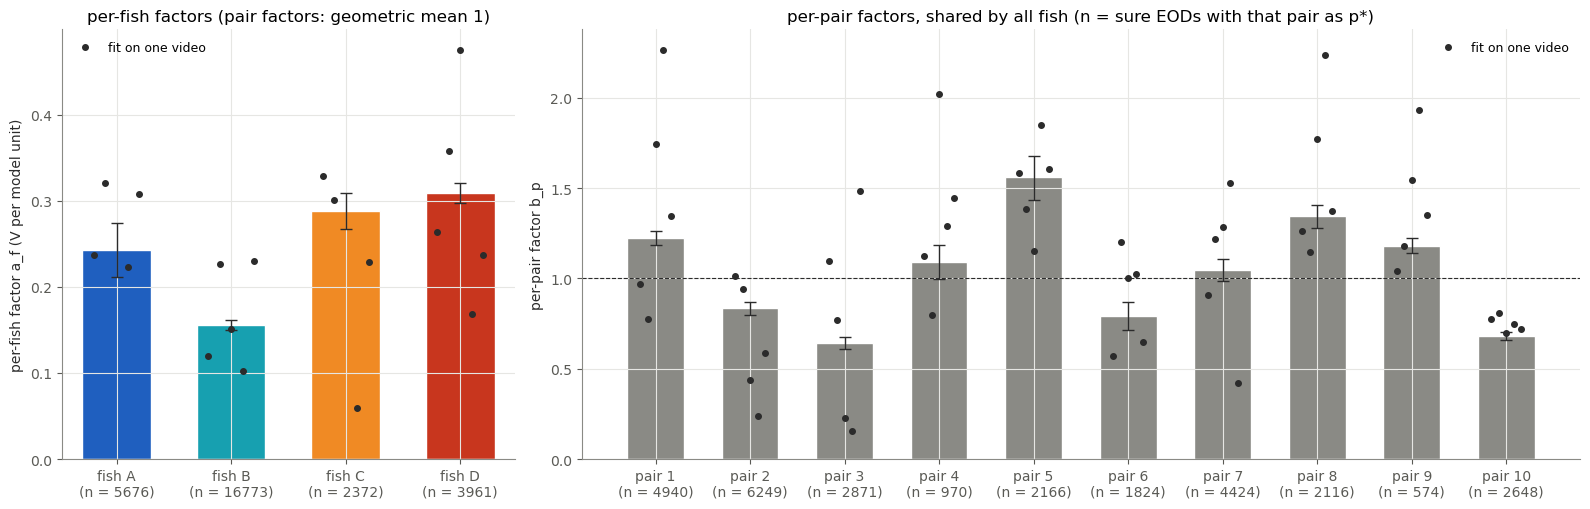

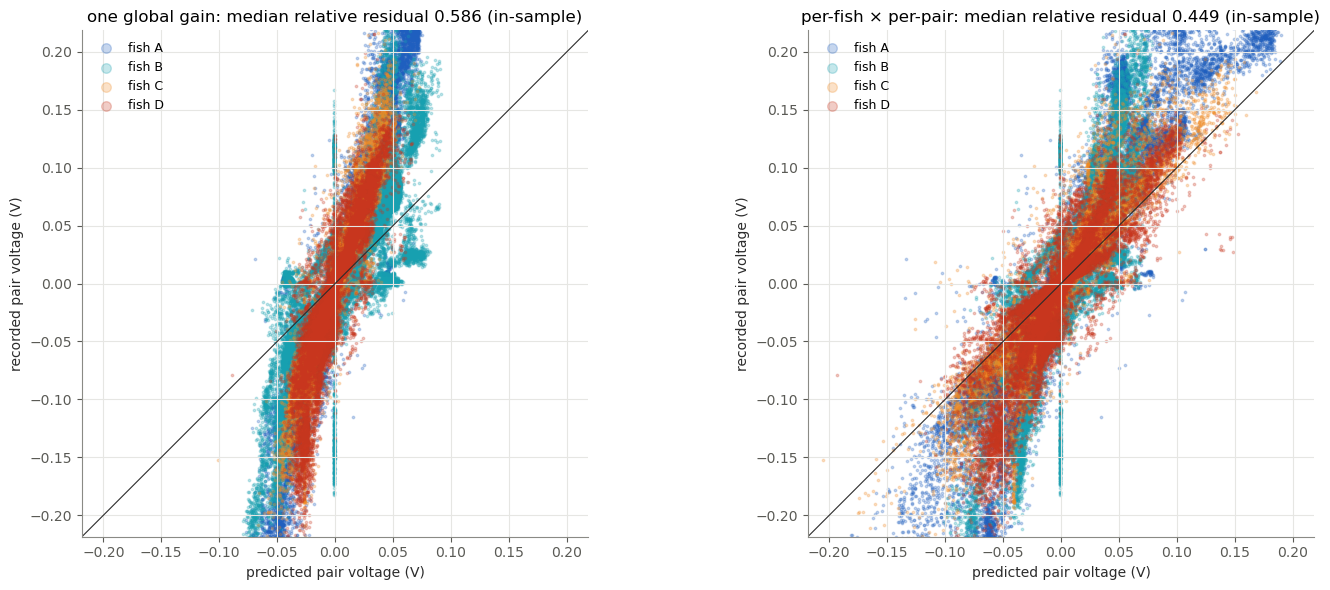

In [5]:
fig, axs = plt.subplots(1, 2, figsize=(16, 5.2), gridspec_kw=dict(width_ratios=[1, 2.2]))
ax = axs[0]
for j, f in enumerate(LET):
    ax.bar(j, a[j], 0.6, color=FISH_COL[f], edgecolor='white')
    ax.errorbar(j, a[j], yerr=[[a[j] - lo[j]], [hi[j] - a[j]]], color='#2b2b2b', capsize=4, lw=1)
    ax.scatter(np.full(len(RECS), j) + np.linspace(-0.2, 0.2, len(RECS)), per_video[:, j], s=16, color='#2b2b2b', zorder=3,
               label='fit on one video' if j == 0 else None)
ax.set(xticks=range(4), xticklabels=[f'fish {f}\n(n = {int((FI == j).sum())})' for j, f in enumerate(LET)],
       ylabel='per-fish factor a_f (V per model unit)', title='per-fish factors (pair factors: geometric mean 1)')
ax.legend(frameon=False, fontsize=9)
ax = axs[1]
x = np.arange(10)
ax.bar(x, b, 0.6, color='#8a8a85', edgecolor='white')
ax.errorbar(x, b, yerr=[b - lo[4:], hi[4:] - b], fmt='none', color='#2b2b2b', capsize=4, lw=1)
for j in range(len(RECS)):
    ax.scatter(x + (j - 2) * 0.08, per_video[j, 4:], s=16, color='#2b2b2b', zorder=3, label='fit on one video' if j == 0 else None)
ax.axhline(1, color='#2b2b2b', lw=0.8, ls='--')
ax.set(xticks=x, xticklabels=[f'pair {p}\n(n = {int((S["pair p* (1-10)"] == p).sum())})' for p in range(1, 11)],
       ylabel='per-pair factor b_p', title='per-pair factors, shared by all fish (n = sure EODs with that pair as p*)')
ax.legend(frameon=False, fontsize=9)
plt.tight_layout(); fig.savefig(f'{OUT}/fish_pair_factors.png', dpi=120); plt.show()

fig, axs = plt.subplots(1, 2, figsize=(15, 6))
for ax, (nm, (aa, bb)) in zip(axs, {'one global gain': fit(Rs, Ms, FI, fish=False, pair=False), 'per-fish × per-pair': (a, b)}.items()):
    pred = aa[FI, None] * bb[None] * Ms
    for j, f in enumerate(LET):
        m = FI == j
        ax.scatter(pred[m].ravel(), Rs[m].ravel(), s=3, alpha=0.25, color=FISH_COL[f], label=f'fish {f}')
    lim = np.percentile(np.abs(Rs), 99.5); ax.plot([-lim, lim], [-lim, lim], color='#2b2b2b', lw=0.8)
    e = rel_resid(Rs, Ms, FI, aa, bb)
    ax.set(xlim=(-lim, lim), ylim=(-lim, lim), aspect='equal', xlabel='predicted pair voltage (V)', ylabel='recorded pair voltage (V)',
           title=f'{nm}: median relative residual {np.median(e):.3f} (in-sample)')
    ax.legend(markerscale=4, frameon=False, fontsize=9)
plt.tight_layout(); fig.savefig(f'{OUT}/predicted_vs_recorded.png', dpi=120); plt.show()